In [1]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.read_gml("../polblogs.gml")

print(type(G))
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

<class 'networkx.classes.multidigraph.MultiDiGraph'>
Number of nodes: 1490
Number of edges: 19090


In [2]:
sample_nodes = list(G.nodes(data=True))[:5]
for n, attrs in sample_nodes:
    print(n, attrs)

100monkeystyping.com {'value': 0, 'source': 'Blogarama'}
12thharmonic.com/wordpress {'value': 0, 'source': 'BlogCatalog'}
40ozblog.blogspot.com {'value': 0, 'source': 'Blogarama,BlogCatalog'}
4lina.tblog.com {'value': 0, 'source': 'Blogarama'}
750volts.blogspot.com {'value': 0, 'source': 'Blogarama'}


In [3]:
G_clean = nx.DiGraph(G)
G_clean.remove_edges_from(nx.selfloop_edges(G_clean))

print("Before cleaning:", G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")
print("After cleaning:", G_clean.number_of_nodes(), "nodes,", G_clean.number_of_edges(), "edges")

Before cleaning: 1490 nodes, 19090 edges
After cleaning: 1490 nodes, 19022 edges


In [4]:
wcc = list(nx.weakly_connected_components(G_clean))
scc = list(nx.strongly_connected_components(G_clean))

print("Weakly connected components:", len(wcc))
print("Largest weakly connected component size:", max(len(c) for c in wcc))

print("Strongly connected components:", len(scc))
print("Largest strongly connected component size:", max(len(c) for c in scc))

isolates = list(nx.isolates(G_clean))
print("Isolated nodes (no edges at all):", len(isolates))

Weakly connected components: 268
Largest weakly connected component size: 1222
Strongly connected components: 688
Largest strongly connected component size: 793
Isolated nodes (no edges at all): 266


In [5]:
density = nx.density(G_clean)
print("Density:", density)

Density: 0.008573836771672354


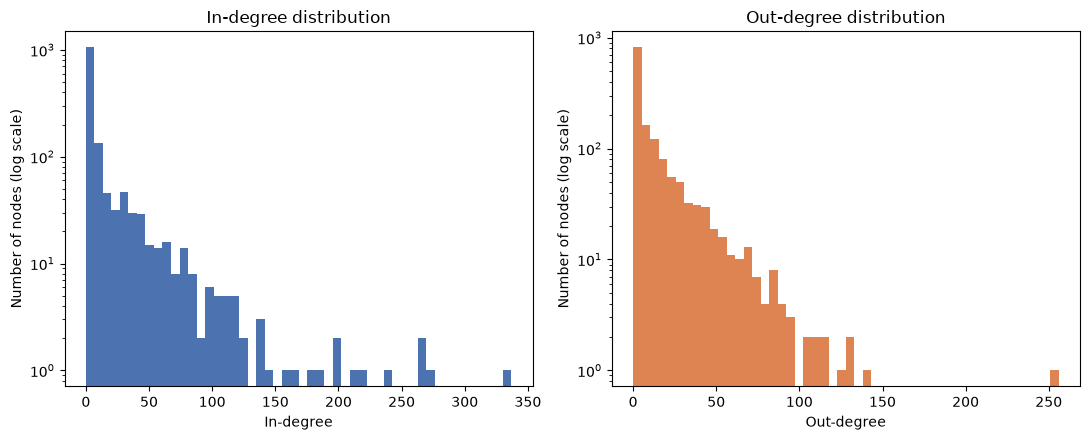

In [6]:
in_deg = [d for n, d in G_clean.in_degree()]
out_deg = [d for n, d in G_clean.out_degree()]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(in_deg, bins=50, color='#4C72B0')
axes[0].set_yscale('log')
axes[0].set_title('In-degree distribution')
axes[0].set_xlabel('In-degree')
axes[0].set_ylabel('Number of nodes (log scale)')
axes[1].hist(out_deg, bins=50, color='#DD8452')
axes[1].set_yscale('log')
axes[1].set_title('Out-degree distribution')
axes[1].set_xlabel('Out-degree')
axes[1].set_ylabel('Number of nodes (log scale)')
plt.tight_layout()
plt.savefig('degree_distribution.png', dpi=150)
plt.show()

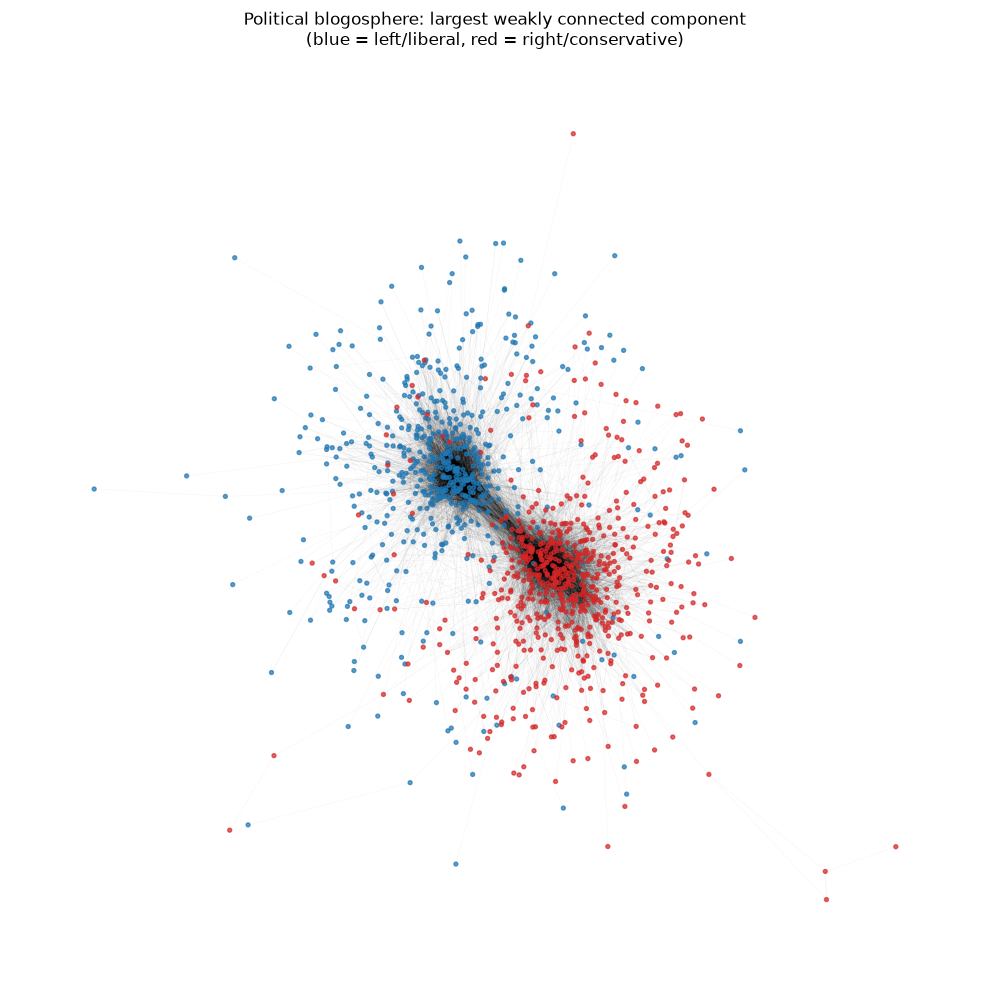

In [7]:
wcc_nodes = max(nx.weakly_connected_components(G_clean), key=len)
G_sub = G_clean.subgraph(wcc_nodes).copy()

pos = nx.spring_layout(G_sub, seed=42, k=0.15, iterations=30)
colors = ['#1f77b4' if G_sub.nodes[n].get('value') == 0 else '#d62728' for n in G_sub.nodes()]

plt.figure(figsize=(10, 10))
nx.draw_networkx_nodes(G_sub, pos, node_size=8, node_color=colors, alpha=0.7)
nx.draw_networkx_edges(G_sub, pos, alpha=0.05, arrows=False, width=0.3)
plt.title('Political blogosphere: largest weakly connected component\n(blue = left/liberal, red = right/conservative)')
plt.axis('off')
plt.tight_layout()
plt.savefig('network_visualization.png', dpi=150)
plt.show()

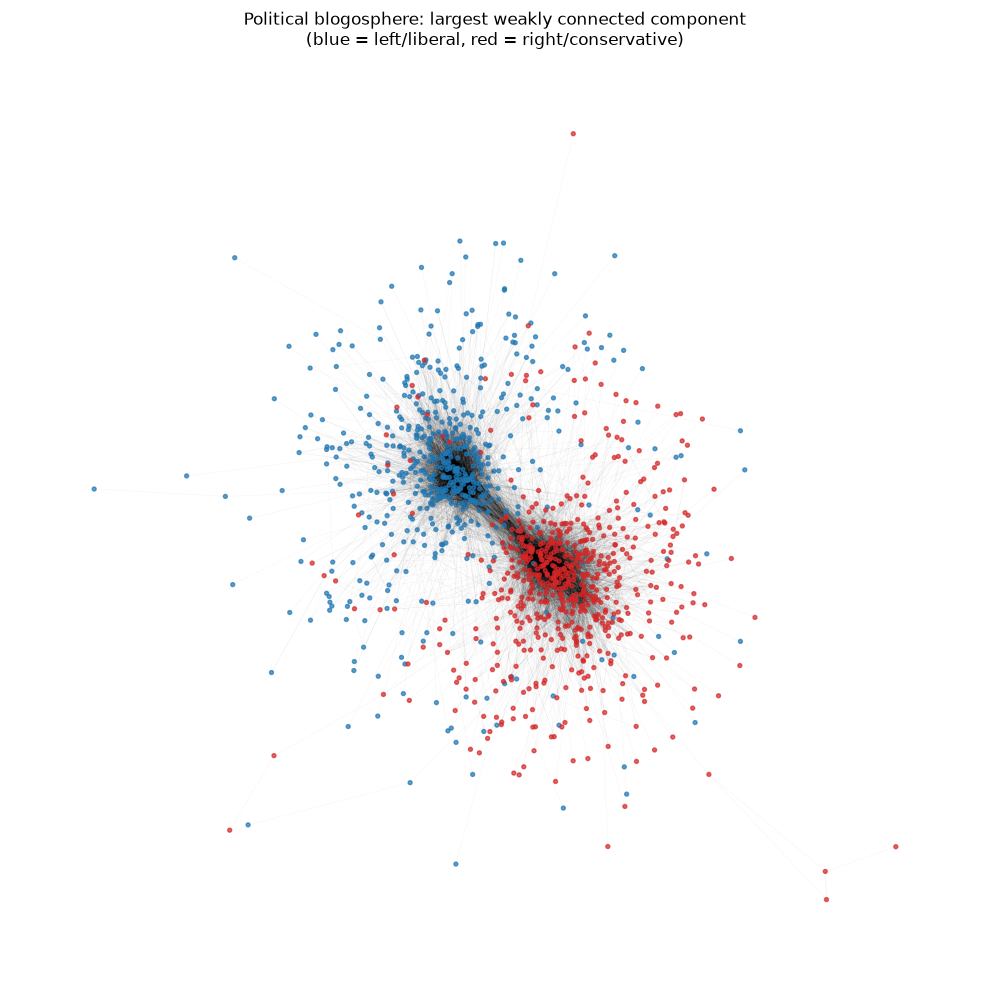

In [8]:
wcc_nodes = max(nx.weakly_connected_components(G_clean), key=len)
G_sub = G_clean.subgraph(wcc_nodes).copy()

pos = nx.spring_layout(G_sub, seed=42, k=0.15, iterations=30)
colors = ['#1f77b4' if G_sub.nodes[n].get('value') == 0 else '#d62728' for n in G_sub.nodes()]

plt.figure(figsize=(10, 10))
nx.draw_networkx_nodes(G_sub, pos, node_size=8, node_color=colors, alpha=0.7)
nx.draw_networkx_edges(G_sub, pos, alpha=0.05, arrows=False, width=0.3)
plt.title('Political blogosphere: largest weakly connected component\n(blue = left/liberal, red = right/conservative)')
plt.axis('off')
plt.tight_layout()
plt.savefig('network_visualization.png', dpi=150)
plt.show()

In [9]:
pagerank = nx.pagerank(G_clean, alpha=0.85)

top10_pagerank = sorted(pagerank.items(), key=lambda x: x[1], reverse=True)[:10]
print("Top 10 by PageRank:")
for rank, (node, score) in enumerate(top10_pagerank, 1):
    print(f"{rank}. {node} -> {score:.5f}")

Top 10 by PageRank:
1. dailykos.com -> 0.01794
2. atrios.blogspot.com -> 0.01521
3. instapundit.com -> 0.01265
4. blogsforbush.com -> 0.01253
5. talkingpointsmemo.com -> 0.01242
6. michellemalkin.com -> 0.01094
7. drudgereport.com -> 0.01073
8. washingtonmonthly.com -> 0.01053
9. powerlineblog.com -> 0.00896
10. andrewsullivan.com -> 0.00862


In [10]:
wcc_nodes = max(nx.weakly_connected_components(G_clean), key=len)
G_sub = G_clean.subgraph(wcc_nodes).copy()

betweenness = nx.betweenness_centrality(G_sub, normalized=True)

top10_betweenness = sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:10]
print("Top 10 by Betweenness:")
for rank, (node, score) in enumerate(top10_betweenness, 1):
    print(f"{rank}. {node} -> {score:.5f}")

Top 10 by Betweenness:
1. blogsforbush.com -> 0.14666
2. atrios.blogspot.com -> 0.06108
3. instapundit.com -> 0.05120
4. dailykos.com -> 0.03691
5. newleftblogs.blogspot.com -> 0.03081
6. madkane.com/notable.html -> 0.03022
7. wizbangblog.com -> 0.02726
8. lashawnbarber.com -> 0.02426
9. hughhewitt.com -> 0.02299
10. washingtonmonthly.com -> 0.02193


In [11]:
from scipy.stats import spearmanr

wcc_nodes = max(nx.weakly_connected_components(G_clean), key=len)
G_sub = G_clean.subgraph(wcc_nodes).copy()

pagerank = nx.pagerank(G_clean, alpha=0.85)
betweenness = nx.betweenness_centrality(G_sub, normalized=True)

common_nodes = list(betweenness.keys())
pr_scores = [pagerank[n] for n in common_nodes]
bw_scores = [betweenness[n] for n in common_nodes]

corr, pval = spearmanr(pr_scores, bw_scores)
print(f"Spearman rank correlation: {corr:.4f} (p={pval:.2e})")

top10_pr = set(n for n, s in sorted(pagerank.items(), key=lambda x: x[1], reverse=True)[:10])
top10_bw = set(n for n, s in sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:10])
overlap = top10_pr & top10_bw
print(f"Top-10 overlap: {len(overlap)} nodes -> {overlap}")

Spearman rank correlation: 0.7576 (p=2.98e-228)
Top-10 overlap: 5 nodes -> {'washingtonmonthly.com', 'instapundit.com', 'atrios.blogspot.com', 'blogsforbush.com', 'dailykos.com'}


In [12]:
import random

wcc_nodes = max(nx.weakly_connected_components(G_clean), key=len)
G_sub = G_clean.subgraph(wcc_nodes).copy()

n_remove = int(0.05 * len(G_sub))  # 61 nodes

# Targeted removal
top_betweenness_nodes = [n for n, s in sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:n_remove]]
G_targeted = G_sub.copy()
G_targeted.remove_nodes_from(top_betweenness_nodes)

# Random removal, fixed seed for reproducibility
random.seed(42)
random_nodes = random.sample(list(G_sub.nodes()), n_remove)
G_random = G_sub.copy()
G_random.remove_nodes_from(random_nodes)

for name, g in [("Original", G_sub), ("Targeted removal", G_targeted), ("Random removal", G_random)]:
    wcc = list(nx.weakly_connected_components(g))
    print(f"{name}: nodes={g.number_of_nodes()}, edges={g.number_of_edges()}, "
          f"density={nx.density(g):.5f}, WCC_count={len(wcc)}, largest_WCC={max(len(c) for c in wcc)}")

Original: nodes=1222, edges=19021, density=0.01275, WCC_count=1, largest_WCC=1222
Targeted removal: nodes=1161, edges=10082, density=0.00749, WCC_count=77, largest_WCC=1082
Random removal: nodes=1161, edges=17404, density=0.01292, WCC_count=4, largest_WCC=1155


In [13]:
import random

wcc_nodes = max(nx.weakly_connected_components(G_clean), key=len)
G_sub = G_clean.subgraph(wcc_nodes).copy()

n_remove = int(0.05 * len(G_sub))  # 61 nodes

# Targeted removal
top_betweenness_nodes = [n for n, s in sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:n_remove]]
G_targeted = G_sub.copy()
G_targeted.remove_nodes_from(top_betweenness_nodes)

# Random removal, fixed seed for reproducibility
random.seed(42)
random_nodes = random.sample(list(G_sub.nodes()), n_remove)
G_random = G_sub.copy()
G_random.remove_nodes_from(random_nodes)

for name, g in [("Original", G_sub), ("Targeted removal", G_targeted), ("Random removal", G_random)]:
    wcc = list(nx.weakly_connected_components(g))
    print(f"{name}: nodes={g.number_of_nodes()}, edges={g.number_of_edges()}, "
          f"density={nx.density(g):.5f}, WCC_count={len(wcc)}, largest_WCC={max(len(c) for c in wcc)}")

Original: nodes=1222, edges=19021, density=0.01275, WCC_count=1, largest_WCC=1222
Targeted removal: nodes=1161, edges=10082, density=0.00749, WCC_count=77, largest_WCC=1082
Random removal: nodes=1161, edges=17404, density=0.01292, WCC_count=4, largest_WCC=1155


In [14]:
import community as community_louvain
import numpy as np

G_undirected = G_sub.to_undirected()
print("Undirected graph:", G_undirected.number_of_nodes(), "nodes,", G_undirected.number_of_edges(), "edges")

n_communities_list = []
modularity_list = []
for seed in range(5):
    partition = community_louvain.best_partition(G_undirected, random_state=seed)
    n_comms = len(set(partition.values()))
    mod = community_louvain.modularity(partition, G_undirected)
    n_communities_list.append(n_comms)
    modularity_list.append(mod)
    print(f"Seed {seed}: {n_comms} communities, modularity={mod:.4f}")

print("Mean communities:", np.mean(n_communities_list), "| Std:", np.std(n_communities_list))
print("Mean modularity:", np.mean(modularity_list), "| Std:", np.std(modularity_list))

# Declared run for the rest of the analysis
partition = community_louvain.best_partition(G_undirected, random_state=1)

Undirected graph: 1222 nodes, 16714 edges
Seed 0: 8 communities, modularity=0.4264
Seed 1: 11 communities, modularity=0.4270
Seed 2: 11 communities, modularity=0.4270
Seed 3: 11 communities, modularity=0.4270
Seed 4: 11 communities, modularity=0.4270
Mean communities: 10.4 | Std: 1.2
Mean modularity: 0.42688176778141534 | Std: 0.0002280899618622691


In [15]:
from collections import Counter
import numpy as np

comm_sizes = Counter(partition.values())
print("Community sizes:", dict(sorted(comm_sizes.items(), key=lambda x: -x[1])))

print(f'{"Community":<10}{"Size":<8}{"Avg PageRank":<15}{"Avg Betweenness":<17}{"Majority label":<15}')
for comm_id in sorted(comm_sizes.keys(), key=lambda c: -comm_sizes[c]):
    nodes_in_comm = [n for n, c in partition.items() if c == comm_id]
    avg_pr = np.mean([pagerank[n] for n in nodes_in_comm])
    avg_bw = np.mean([betweenness[n] for n in nodes_in_comm])
    labels = [G_sub.nodes[n].get('value') for n in nodes_in_comm]
    majority = 'left(0)' if labels.count(0) > labels.count(1) else 'right(1)'
    purity = max(labels.count(0), labels.count(1)) / len(labels)
    print(f'{comm_id:<10}{comm_sizes[comm_id]:<8}{avg_pr:<15.6f}{avg_bw:<17.6f}{majority:<15} (purity={purity:.2f})')

Community sizes: {2: 631, 0: 529, 3: 39, 9: 5, 5: 4, 7: 3, 10: 3, 1: 2, 6: 2, 8: 2, 4: 2}
Community Size    Avg PageRank   Avg Betweenness  Majority label 
2         631     0.000787       0.001250         right(1)        (purity=0.95)
0         529     0.000821       0.001451         left(0)         (purity=0.97)
3         39      0.000304       0.000245         left(0)         (purity=0.72)
9         5       0.000482       0.001220         right(1)        (purity=0.80)
5         4       0.000269       0.000239         left(0)         (purity=0.75)
7         3       0.000209       0.000009         left(0)         (purity=1.00)
10        3       0.000254       0.000000         right(1)        (purity=1.00)
1         2       0.000256       0.000346         left(0)         (purity=1.00)
6         2       0.000274       0.000000         left(0)         (purity=1.00)
8         2       0.000268       0.000322         left(0)         (purity=1.00)
4         2       0.000214       0.000000   

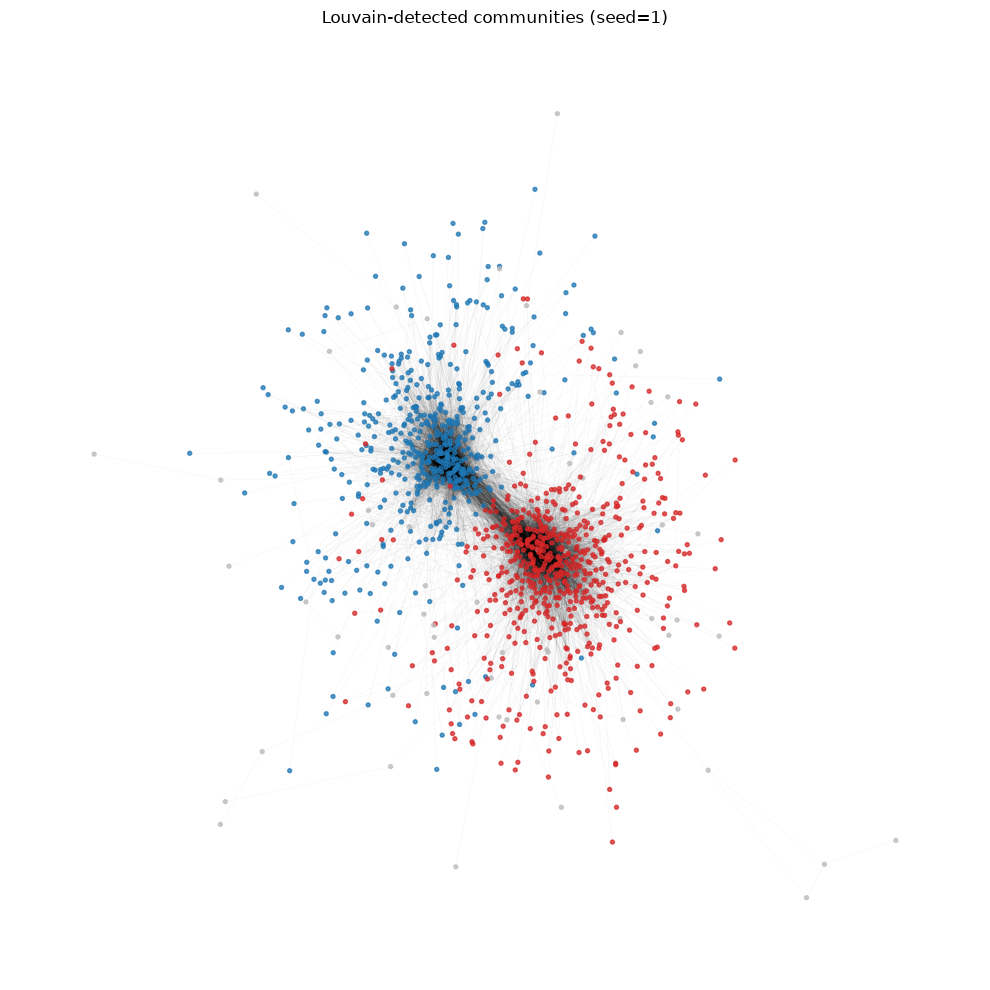

In [16]:
pos = nx.spring_layout(G_undirected, seed=42, k=0.15, iterations=30)
color_map = {2: '#d62728', 0: '#1f77b4'}   # <- update these IDs if yours differ
colors = [color_map.get(partition[n], '#bbbbbb') for n in G_undirected.nodes()]

plt.figure(figsize=(10, 10))
nx.draw_networkx_nodes(G_undirected, pos, node_size=8, node_color=colors, alpha=0.75)
nx.draw_networkx_edges(G_undirected, pos, alpha=0.05, width=0.3)
plt.title('Louvain-detected communities (seed=1)')
plt.axis('off')
plt.tight_layout()
plt.savefig('community_visualization.png', dpi=150)
plt.show()

In [17]:
from collections import Counter

def run_louvain(G, name):
    G_und = G.to_undirected()
    partition = community_louvain.best_partition(G_und, random_state=1)
    mod = community_louvain.modularity(partition, G_und)
    sizes = Counter(partition.values())
    n_comms = len(sizes)
    top2 = sorted(sizes.values(), reverse=True)[:2]
    print(f"=== {name} ===")
    print(f"Nodes: {G.number_of_nodes()}, Communities: {n_comms}, Modularity: {mod:.4f}")
    print(f"Top 2 community sizes: {top2}")
    return partition, mod, n_comms

partition_orig, mod_orig, n_orig = run_louvain(G_sub, "Original")
partition_targeted, mod_targeted, n_targeted = run_louvain(G_targeted, "Targeted removal (top-betweenness)")
partition_random, mod_random, n_random = run_louvain(G_random, "Random removal")

=== Original ===
Nodes: 1222, Communities: 11, Modularity: 0.4270
Top 2 community sizes: [631, 529]
=== Targeted removal (top-betweenness) ===
Nodes: 1161, Communities: 90, Modularity: 0.4461
Top 2 community sizes: [448, 351]
=== Random removal ===
Nodes: 1161, Communities: 14, Modularity: 0.4236
Top 2 community sizes: [614, 483]


In [18]:
def pairwise_eval(G, partition, name):
    nodes = list(G.nodes())
    comm = np.array([partition[n] for n in nodes])
    label = np.array([G.nodes[n].get('value') for n in nodes])

    same_comm = comm[:, None] == comm[None, :]
    same_label = label[:, None] == label[None, :]

    iu = np.triu_indices(len(nodes), k=1)
    same_comm = same_comm[iu]
    same_label = same_label[iu]

    TP = np.sum(same_comm & same_label)
    TN = np.sum(~same_comm & ~same_label)
    FP = np.sum(same_comm & ~same_label)
    FN = np.sum(~same_comm & same_label)

    total = TP + TN + FP + FN
    accuracy = (TP + TN) / total
    precision = TP / (TP + FP) if (TP + FP) > 0 else float('nan')
    recall = TP / (TP + FN) if (TP + FN) > 0 else float('nan')
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else float('nan')
    mod = community_louvain.modularity(partition, G.to_undirected())

    print(f"=== {name} ===")
    print(f"TP={TP}, TN={TN}, FP={FP}, FN={FN}, total={total}")
    print(f"Accuracy={accuracy:.4f}, Precision={precision:.4f}, Recall={recall:.4f}, F1={f1:.4f}, Modularity={mod:.4f}")
    return dict(TP=TP, TN=TN, FP=FP, FN=FN, accuracy=accuracy, precision=precision, recall=recall, f1=f1, modularity=mod)

results_orig = pairwise_eval(G_sub, partition_orig, "Original")
results_targeted = pairwise_eval(G_targeted, partition_targeted, "Targeted removal")
results_random = pairwise_eval(G_random, partition_random, "Random removal")

=== Original ===
TP=313633, TN=347141, FP=25555, FN=59702, total=746031
Accuracy=0.8857, Precision=0.9247, Recall=0.8401, F1=0.8803, Modularity=0.4270
=== Targeted removal ===
TP=171356, TN=316638, FP=19472, FN=165914, total=673380
Accuracy=0.7247, Precision=0.8980, Recall=0.5081, F1=0.6490, Modularity=0.4461
=== Random removal ===
TP=278560, TN=309350, FP=26760, FN=58710, total=673380
Accuracy=0.8731, Precision=0.9124, Recall=0.8259, F1=0.8670, Modularity=0.4236


## Part F: Reproducibility, Seeds, and Conclusion

**Seeds used in this notebook:**
- `spring_layout(seed=42)` — used for all network visualizations
- `community_louvain.best_partition(random_state=0..4)` — 5-seed stability check for Louvain
- `community_louvain.best_partition(random_state=1)` — declared run used for all reported results, figures, and tables
- `random.seed(42)` — used to select nodes for the random-removal experiment

**Conclusion:**

This analysis found that the political blogosphere's hyperlink structure strongly reflects real-world political alignment: Louvain community detection, using no political information, recovered two dominant communities (631 and 529 nodes) that matched the true left/right labels with 95-97% purity, yielding an overall pairwise F1 score of 0.88. PageRank and Betweenness centrality, while moderately correlated (Spearman correlation 0.76), identified different kinds of important nodes — PageRank surfaced high-authority blogs like dailykos.com and instapundit.com, while betweenness isolated a small set of structural bridges such as blogsforbush.com that connect the two political camps. Removing the top 5% of betweenness-ranked nodes fragmented the network from 11 to 90 communities and dropped classification accuracy from 88.6% to 72.5% (F1 dropping to 0.65), while removing the same number of random nodes left results almost unchanged (87.3% accuracy) — confirming that a small number of structurally central blogs, not just any nodes, hold the network's community structure together.

**Limitations:** these results reflect the political blogosphere as it existed in February 2005, around the 2004 U.S. election, and may not generalize to other periods or platforms. More importantly, a hyperlink is not necessarily an endorsement — blogs frequently link to opposing views to criticize or rebut them, so some cross-community edges may actually represent disagreement rather than alignment, meaning the true separation between political communities could be even stronger than the link structure alone suggests.